In [3]:

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import os

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
GPU available: True


In [4]:

DATA_PATH = "./cifar_data"

transform = transforms.ToTensor()


train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)


test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

print("Dataset loaded successfully!")
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


100%|██████████| 170M/170M [17:34<00:00, 162kB/s]


Dataset loaded successfully!
Training images: 50000
Testing images: 10000


In [5]:

print("Dataset Classes:")
print(train_dataset.classes)

print("\nFirst Image Shape:")
print(train_dataset[0][0].shape)

print("\nFirst Image Label:")
print(train_dataset[0][1])


Dataset Classes:
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

First Image Shape:
torch.Size([3, 32, 32])

First Image Label:
6


In [6]:

import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        # Convolutional layers
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Max pooling layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

# Set device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create model
model = CNN().to(device)

print(model)


CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [7]:

import torch.optim as optim

def train(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

print("Training function defined successfully!")


Training function defined successfully!


In [8]:

def test(model, test_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss = running_loss / total
    test_accuracy = 100 * correct / total

    return test_loss, test_accuracy

print("Testing function defined successfully!")


Testing function defined successfully!


In [9]:

from torch.utils.data import DataLoader

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

# Get one batch of images
images, labels = next(iter(train_loader))

print("Images Tensor Size:", images.shape)
print("Labels Tensor Size:", labels.shape)
print("Single Image Size:", images[0].shape)


Images Tensor Size: torch.Size([64, 3, 32, 32])
Labels Tensor Size: torch.Size([64])
Single Image Size: torch.Size([3, 32, 32])


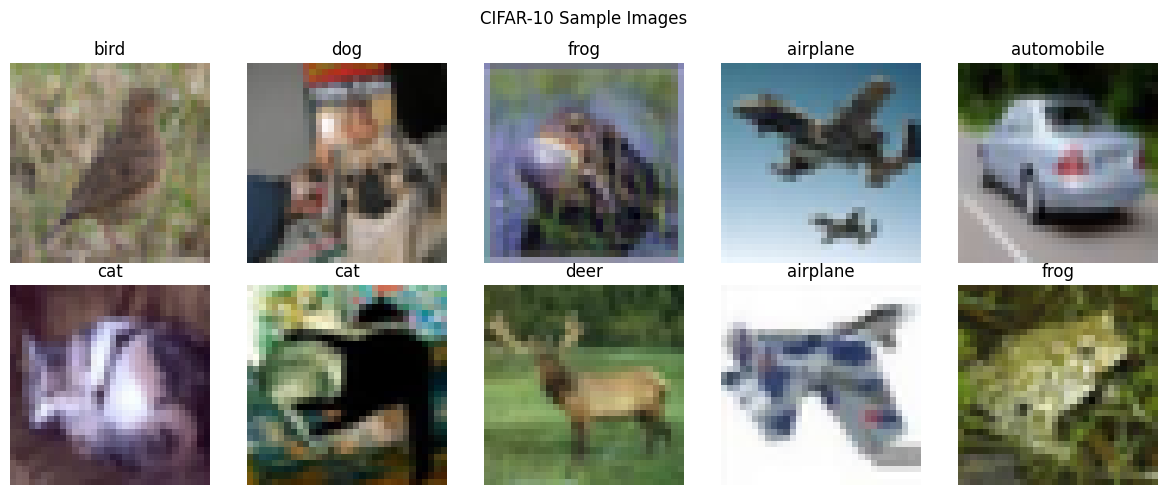

In [10]:

import numpy as np
import matplotlib.pyplot as plt

classes = train_dataset.classes

# Display 10 images from the batch
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()
    ax.imshow(image)
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images")
plt.tight_layout()
plt.show()


In [11]:

from torchvision import transforms

# Add Gaussian noise to images
class AddGaussianNoise:
    def __init__(self, mean=0.0, std=0.03):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        noise = torch.randn_like(tensor) * self.std
        return tensor + noise + self.mean

# Training data augmentation
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomResizedCrop(
        size=32,
        scale=(0.8, 1.0)
    ),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    AddGaussianNoise(mean=0.0, std=0.03),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

# Test data: No random augmentation
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

print("Augmentation transforms defined successfully!")


Augmentation transforms defined successfully!


In [12]:

# Load datasets with augmentation
train_dataset_aug = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=train_transform
)

test_dataset_aug = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform
)

# Create augmented data loaders
train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=64,
    shuffle=True
)

test_loader_aug = DataLoader(
    test_dataset_aug,
    batch_size=64,
    shuffle=False
)

print("Augmented training images:", len(train_dataset_aug))
print("Test images:", len(test_dataset_aug))
print("Augmented DataLoaders created successfully!")


Augmented training images: 50000
Test images: 10000
Augmented DataLoaders created successfully!


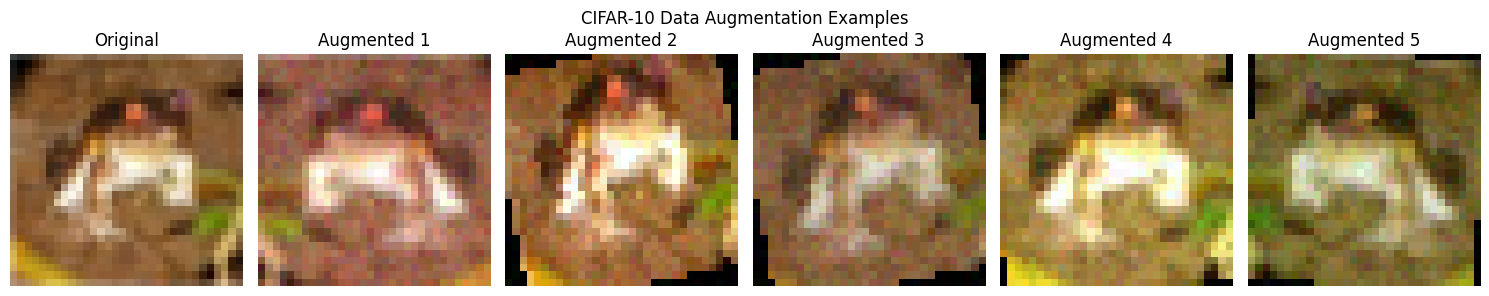

In [13]:

import matplotlib.pyplot as plt

# Choose one image from original dataset
original_image, label = train_dataset[0]

# Create 5 augmented versions
fig, axes = plt.subplots(1, 6, figsize=(15, 3))

# Show original image
axes[0].imshow(original_image.permute(1, 2, 0))
axes[0].set_title("Original")
axes[0].axis("off")

# CIFAR-10 normalization values
mean = torch.tensor([0.4914, 0.4822, 0.4465])
std = torch.tensor([0.2470, 0.2435, 0.2616])

# Show augmented versions
for i in range(1, 6):
    augmented_image, _ = train_dataset_aug[0]

    # Reverse normalization for visualization
    augmented_image = (
        augmented_image * std[:, None, None]
        + mean[:, None, None]
    )

    augmented_image = augmented_image.clamp(0, 1)

    axes[i].imshow(
        augmented_image.permute(1, 2, 0)
    )
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")

plt.suptitle("CIFAR-10 Data Augmentation Examples")
plt.tight_layout()
plt.show()


In [14]:

import time
import torch.optim as optim

def run_experiment(
    model,
    train_loader,
    test_loader,
    learning_rate=0.001,
    epochs=5
):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "test_loss": [],
        "test_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = train(
            model, train_loader,
            criterion, optimizer, device
        )

        test_loss, test_acc = test(
            model, test_loader,
            criterion, device
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_acc)

        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc:.2f}%"
        )

    elapsed = time.time() - start_time
    print(f"\nTraining Time: {elapsed:.1f} seconds")

    return history

print("Experiment function ready!")


Experiment function ready!


In [15]:

# Experiment 1: Baseline CNN

torch.manual_seed(42)

model1 = CNN()

history1 = run_experiment(
    model=model1,
    train_loader=train_loader,
    test_loader=test_loader,
    learning_rate=0.001,
    epochs=5
)

print("\nExperiment 1 Final Results:")
print("Train Loss:", history1["train_loss"][-1])
print("Test Loss:", history1["test_loss"][-1])
print("Test Accuracy:", history1["test_accuracy"][-1])


Epoch [1/5] | Train Loss: 1.4755 | Train Acc: 46.84% | Test Loss: 1.1967 | Test Acc: 57.45%
Epoch [2/5] | Train Loss: 1.1160 | Train Acc: 60.34% | Test Loss: 1.0312 | Test Acc: 63.65%
Epoch [3/5] | Train Loss: 0.9577 | Train Acc: 66.38% | Test Loss: 0.9741 | Test Acc: 66.03%
Epoch [4/5] | Train Loss: 0.8524 | Train Acc: 69.90% | Test Loss: 0.9048 | Test Acc: 68.86%
Epoch [5/5] | Train Loss: 0.7740 | Train Acc: 72.84% | Test Loss: 0.9058 | Test Acc: 69.39%

Training Time: 52.8 seconds

Experiment 1 Final Results:
Train Loss: 0.774007268486023
Test Loss: 0.9058415935516357
Test Accuracy: 69.39


In [16]:

# Experiment 2: Augmented CNN

torch.manual_seed(42)

model2 = CNN()

history2 = run_experiment(
    model=model2,
    train_loader=train_loader_aug,
    test_loader=test_loader_aug,
    learning_rate=0.0005,
    epochs=5
)

print("\nExperiment 2 Final Results:")
print("Train Loss:", history2["train_loss"][-1])
print("Test Loss:", history2["test_loss"][-1])
print("Test Accuracy:", history2["test_accuracy"][-1])


Epoch [1/5] | Train Loss: 1.5900 | Train Acc: 42.97% | Test Loss: 1.3119 | Test Acc: 53.94%
Epoch [2/5] | Train Loss: 1.3196 | Train Acc: 53.04% | Test Loss: 1.1349 | Test Acc: 59.15%
Epoch [3/5] | Train Loss: 1.1955 | Train Acc: 58.05% | Test Loss: 1.0133 | Test Acc: 65.16%
Epoch [4/5] | Train Loss: 1.1168 | Train Acc: 60.72% | Test Loss: 0.9904 | Test Acc: 66.22%
Epoch [5/5] | Train Loss: 1.0661 | Train Acc: 62.60% | Test Loss: 0.9314 | Test Acc: 67.29%

Training Time: 333.9 seconds

Experiment 2 Final Results:
Train Loss: 1.066057571258545
Test Loss: 0.9314393646240234
Test Accuracy: 67.29


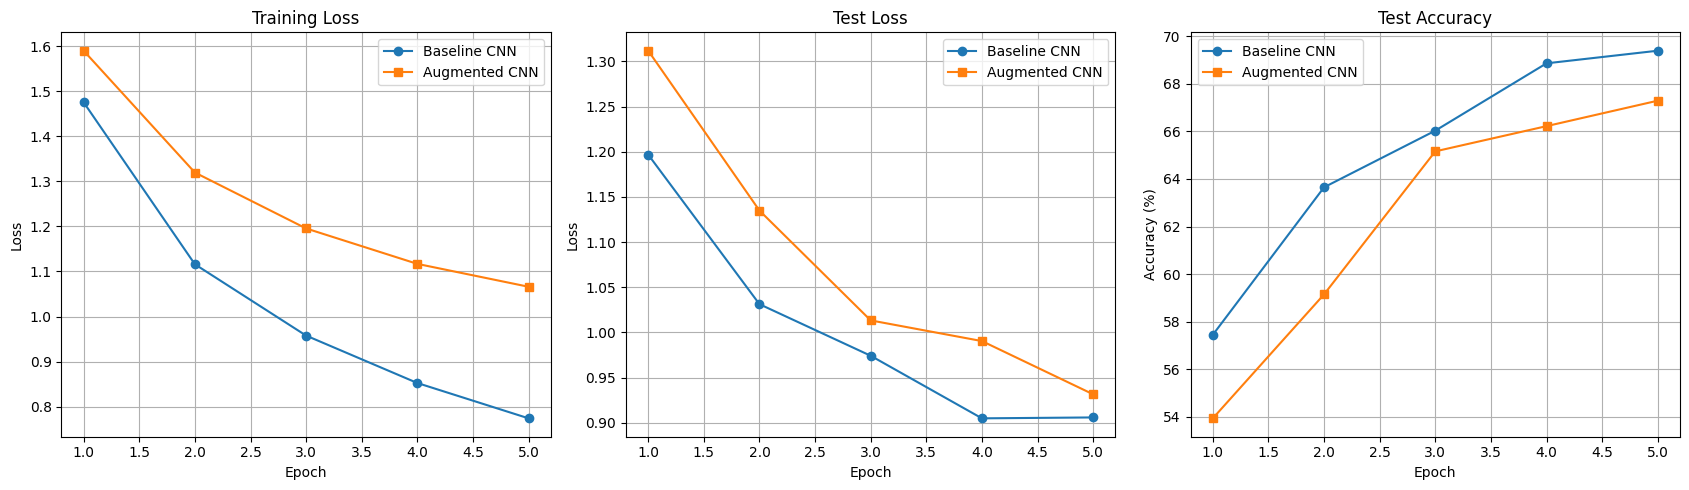

In [17]:

import matplotlib.pyplot as plt

epochs1 = range(1, len(history1["train_loss"]) + 1)
epochs2 = range(1, len(history2["train_loss"]) + 1)

metrics = [
    ("train_loss", "Training Loss", "Loss"),
    ("test_loss", "Test Loss", "Loss"),
    ("test_accuracy", "Test Accuracy", "Accuracy (%)")
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (key, title, ylabel) in zip(axes, metrics):
    ax.plot(
        epochs1, history1[key],
        marker="o", label="Baseline CNN"
    )
    ax.plot(
        epochs2, history2[key],
        marker="s", label="Augmented CNN"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig("cnn_training_plots.png", dpi=200)
plt.show()


In [18]:

import pandas as pd

results = pd.DataFrame({
    "Experiment": [
        "Baseline CNN",
        "Augmented CNN"
    ],
    "Learning Rate": [0.001, 0.0005],
    "Batch Size": [64, 64],
    "Epochs": [5, 5],
    "Train Loss": [
        history1["train_loss"][-1],
        history2["train_loss"][-1]
    ],
    "Test Loss": [
        history1["test_loss"][-1],
        history2["test_loss"][-1]
    ],
    "Test Accuracy (%)": [
        history1["test_accuracy"][-1],
        history2["test_accuracy"][-1]
    ]
})

display(results.round(4))

best = results.loc[
    results["Test Accuracy (%)"].idxmax()
]

print("\nBest Experiment:", best["Experiment"])
print("Best Test Accuracy:", best["Test Accuracy (%)"])


,Experiment,Learning Rate,Batch Size,Epochs,Train Loss,Test Loss,Test Accuracy (%)
0,Baseline CNN,0.0010,64,5,0.7740,0.9058,69.39
1,Augmented CNN,0.0005,64,5,1.0661,0.9314,67.29



Best Experiment: Baseline CNN
Best Test Accuracy: 69.39


In [19]:

class ImprovedCNN(nn.Module):
    def __init__(self):
        super(ImprovedCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

print(ImprovedCNN())


ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [20]:

# Experiment 3: Improved CNN

torch.manual_seed(42)

train_loader_128 = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader_128 = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

model3 = ImprovedCNN()

history3 = run_experiment(
    model=model3,
    train_loader=train_loader_128,
    test_loader=test_loader_128,
    learning_rate=0.001,
    epochs=5
)

print("\nExperiment 3 Final Results:")
print("Train Loss:", history3["train_loss"][-1])
print("Test Loss:", history3["test_loss"][-1])
print("Test Accuracy:", history3["test_accuracy"][-1])


Epoch [1/5] | Train Loss: 1.6431 | Train Acc: 39.49% | Test Loss: 1.3271 | Test Acc: 51.88%
Epoch [2/5] | Train Loss: 1.2892 | Train Acc: 53.42% | Test Loss: 1.1465 | Test Acc: 59.38%
Epoch [3/5] | Train Loss: 1.1199 | Train Acc: 60.14% | Test Loss: 1.0088 | Test Acc: 64.69%
Epoch [4/5] | Train Loss: 0.9925 | Train Acc: 64.78% | Test Loss: 0.9110 | Test Acc: 68.16%
Epoch [5/5] | Train Loss: 0.8953 | Train Acc: 68.70% | Test Loss: 0.8683 | Test Acc: 69.57%

Training Time: 51.0 seconds

Experiment 3 Final Results:
Train Loss: 0.8953163220596313
Test Loss: 0.8682851623535156
Test Accuracy: 69.57


In [21]:

final_results = pd.DataFrame({
    "Experiment": [
        "Baseline CNN",
        "Augmented CNN",
        "Improved CNN"
    ],
    "Architecture": [
        "2 Conv Layers",
        "2 Conv Layers",
        "3 Conv Layers"
    ],
    "Learning Rate": [0.001, 0.0005, 0.001],
    "Batch Size": [64, 64, 128],
    "Epochs": [5, 5, 5],
    "Train Loss": [
        history1["train_loss"][-1],
        history2["train_loss"][-1],
        history3["train_loss"][-1]
    ],
    "Test Loss": [
        history1["test_loss"][-1],
        history2["test_loss"][-1],
        history3["test_loss"][-1]
    ],
    "Test Accuracy (%)": [
        history1["test_accuracy"][-1],
        history2["test_accuracy"][-1],
        history3["test_accuracy"][-1]
    ]
})

display(final_results.round(4))

best = final_results.loc[
    final_results["Test Accuracy (%)"].idxmax()
]

print("\nBest Model:", best["Experiment"])
print("Best Test Accuracy:", best["Test Accuracy (%)"])


,Experiment,Architecture,Learning Rate,Batch Size,Epochs,Train Loss,Test Loss,Test Accuracy (%)
0,Baseline CNN,2 Conv Layers,0.0010,64,5,0.7740,0.9058,69.39
1,Augmented CNN,2 Conv Layers,0.0005,64,5,1.0661,0.9314,67.29
2,Improved CNN,3 Conv Layers,0.0010,128,5,0.8953,0.8683,69.57



Best Model: Improved CNN
Best Test Accuracy: 69.57


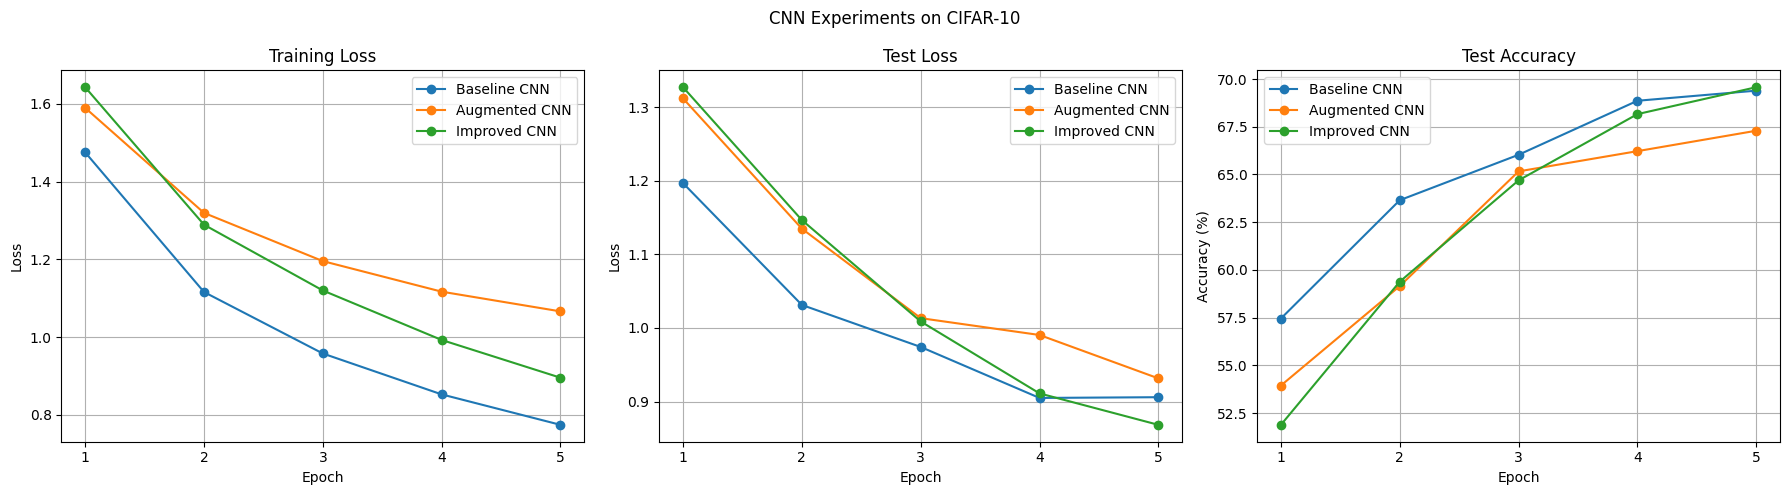

In [22]:

import matplotlib.pyplot as plt

histories = {
    "Baseline CNN": history1,
    "Augmented CNN": history2,
    "Improved CNN": history3
}

metrics = [
    ("train_loss", "Training Loss", "Loss"),
    ("test_loss", "Test Loss", "Loss"),
    ("test_accuracy", "Test Accuracy", "Accuracy (%)")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (metric, title, ylabel) in zip(axes, metrics):
    for name, history in histories.items():
        epochs = range(1, len(history[metric]) + 1)
        ax.plot(
            epochs,
            history[metric],
            marker="o",
            label=name
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, 6))
    ax.legend()
    ax.grid(True)

plt.suptitle("CNN Experiments on CIFAR-10")
plt.tight_layout()
plt.savefig("final_cnn_results.png", dpi=300)
plt.show()
